## Lab 8
**Time Series Forecasting with Airline Passengers: Decomposition, Stationarity, SARIMA Modeling, and System-Aware Evaluation**



## Learning Objectives

By the end of this lab, you will be able to:

1. **Acquire** the classic Airline Passengers dataset and **validate** schema, missingness, datetime index, and data integrity for forecasting readiness.
2. **Explore** time-series structure using rolling statistics and **identify** trend, seasonality, and variance patterns that guide model selection.
3. **Decompose** a time series into trend, seasonal, and residual components using additive decomposition and **interpret** whether the decomposition is appropriate.
4. **Evaluate** stationarity using the Augmented Dickey-Fuller test and **apply** differencing transformations to achieve stationarity.
5. **Engineer** temporal features (month, year) and **explain** when they are needed vs. when model structure handles them.
6. **Compare** a simple exponential smoothing baseline against a SARIMA model and **justify** the added complexity.
7. **Implement** rolling-origin (expanding window) backtesting and **explain** why random cross-validation is invalid for time series.
8. **Diagnose** model performance via residual analysis, ACF plots, and forecast visualizations.
9. **Design** a minimal monitoring plan for a production forecasting system (forecast drift, residual autocorrelation, prediction interval coverage).





## Tasks

- Load the Airline Passengers dataset and convert the `Month` column into a proper `DatetimeIndex`.
- Validate schema: types, missing values, datetime range, and summary statistics.
- Compute and plot a 12-month rolling mean to visualize trend.
- Perform additive seasonal decomposition (period=12) and interpret each component.
- Run the Augmented Dickey-Fuller test on the raw series; interpret the result.
- Apply first-order differencing and assess the effect on stationarity.
- Engineer month and year features from the datetime index.
- Build an Exponential Weighted Moving Average (EWMA) baseline with α=0.3.
- Fit a SARIMA(1,1,1)(1,1,1,12) model and interpret the summary output.
- Implement rolling-origin backtesting; report MAE and RMSE.
- Analyze residuals and ACF to assess whether the model captures all structure.
- Define monitoring metrics for a production forecasting system.



**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.



## References

### Official Documentation
- `statsmodels.tsa.seasonal.seasonal_decompose`: https://www.statsmodels.org/stable/generated/statsmodels.tsa.seasonal.seasonal_decompose.html
- `statsmodels.tsa.stattools.adfuller`: https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html
- `statsmodels.tsa.statespace.sarimax.SARIMAX`: https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html
- `statsmodels.graphics.tsaplots.plot_acf`: https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html
- `statsmodels.graphics.tsaplots.plot_pacf`: https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html
- `sklearn.metrics.mean_absolute_error`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html
- `sklearn.metrics.mean_squared_error`: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html

### Textbook & Guides
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.): https://otexts.com/fpp3/
- statsmodels Time Series Analysis Guide: https://www.statsmodels.org/stable/tsa.html
- Box-Jenkins Methodology: https://en.wikipedia.org/wiki/Box%E2%80%93Jenkins_method

### Python Commands / Quick Reference
- **Data:** `pd.read_csv()`, `pd.to_datetime()`, `.set_index()`, `.isnull().sum()`, `.describe()`
- **EDA:** `ts.rolling(12).mean()`, `ts.diff()`, `ts.ewm(alpha=0.3).mean()`
- **Decomposition:** `seasonal_decompose(ts, model='additive', period=12)`
- **Stationarity:** `adfuller(ts)` → (adf_stat, p_value, usedlag, nobs, critical_values, icbest)
- **Modeling:** `SARIMAX(ts, order=(p,d,q), seasonal_order=(P,D,Q,m))`, `.fit()`, `.forecast()`
- **Diagnostics:** `plot_acf(resid)`, `plot_pacf(resid)`, `fit_model.resid`
- **Metrics:** `mean_absolute_error(y_true, y_pred)`, `mean_squared_error(y_true, y_pred)`
- **Plotting:** `plt.plot()`, `plt.fill_between()`, `plt.legend()`, `plt.show()`





## Workflow Overview

1. Setup & reproducibility (seed, imports, figure defaults)
2. Data acquisition (Airline Passengers CSV from GitHub)
3. Data validation (schema, missingness, datetime index, summary stats)
4. Exploratory analysis (rolling mean, visual trend/seasonality detection)
5. Time-series decomposition (additive; trend + seasonal + residual)
6. Stationarity testing (ADF test + differencing)
7. Feature engineering (month, year extraction)
8. Baseline forecasting (exponential smoothing)
9. SARIMA modeling (fit, interpret, forecast)
10. Rolling-origin backtesting (expanding window, MAE/RMSE)
11. Diagnostics & monitoring (residuals, ACF, production metrics)





## Dataset

**Primary dataset:** [Airline Passengers](https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv) (Box & Jenkins, 1976)

- **144 monthly observations** from January 1949 to December 1960
- **1 numeric column:** `Passengers` (thousands of international airline passengers)
- **Datetime index:** `Month` (first day of each month)
- **Key characteristics:** Strong upward trend, multiplicative seasonality (amplitude grows with level), no missing values
- This is one of the most widely studied time-series datasets and serves as a benchmark for classical forecasting methods


# Step 1 — Reproducible Setup

### Pre-coding Questions

1. Why is random train/test splitting invalid for time series?  
The random train/test split is not valid since it violates the temporal order of the observations. The forecasting model should be trained on past data and tested on future data. By randomly splitting the data, it would be possible to include some future information in the train dataset and make the model overly optimistic about its performance.


2. What type of leakage occurs if timestamps are shuffled?      
Shuffling timestamps can cause temporal leakage, where future observations become part of the training data while earlier observations are used for testing. This allows the model to indirectly learn information that would not have been available at prediction time.


3. Why is reproducibility important when evaluating forecasting models?     
The reproducibility will ensure that the same data, parameters, and random factors lead to the same results. It also allows comparing different models, debugging the code, auditing, and evaluating the experiment. The lab explicitly mentions reproducibility in the context of debugging, auditing, and peer review.



### Functions to Explore

- `numpy.random.seed()`
- `pandas.read_csv()`


In [1]:
# pip install --upgrade statsmodels

In [2]:
# Environment setup

import warnings
warnings.filterwarnings('ignore')  # suppress convergence / frequency warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# sklearn — evaluation utilities
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

# statsmodels — time-series analysis & modeling
from statsmodels.tsa.stattools import adfuller            # stationarity test
from statsmodels.tsa.seasonal import STL, seasonal_decompose  # decomposition
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  # ACF / PACF plots
from statsmodels.tsa.statespace.sarimax import SARIMAX         # SARIMA model

# reproducibility
np.random.seed(42)
plt.rcParams['figure.figsize'] = (12, 4)  # default figure size for all plots

print("Environment ready")
warnings.filterwarnings('ignore')

Environment ready


**Note:**

Setting a random seed (`np.random.seed(42)`) ensures that any stochastic component in our pipeline produces identical results across runs. This is a foundational practice in ML systems — without reproducibility, debugging, auditing, and peer review become impossible. Always pin your seeds and record library versions.


# Step 2 — Data Acquisition and Validation



**Pre-coding questions**

1. Why must time series models use regular time intervals?      
Time series models rely on the spacing between observations to understand trends, seasonality, and temporal relationships. Regular intervals make it possible to correctly interpret lags and seasonal patterns. For example, this dataset has one observation for every month, which allows a seasonal period of 12 to represent yearly seasonality.
   


3. What problems occur if timestamps are missing?       
Missing timestamps can cause the gaps in the time series which can mislead the model about the actual time between observations. This will affect any calculation of lag, seasonality, rolling statistics, decomposition and forecasting. A production system might need to handle missing timestamps and decide whether to fill them in or not.


4. Why might interpolation introduce leakage in some situations?        
Interpolation can lead to leakage by using information from observations that occur in the future relative to the forecast being predicted. An example of this would be predicting a missing value that uses both preceding and succeeding observations, which would use data that would not have been available at the time of forecasting.


Dataset: **Airline Passengers Dataset**

Source:
https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv





Convert the Month column into a datetime index and extract the passenger series.

In [3]:
# Load the Airline Passengers dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
data = pd.read_csv(url)

# Convert 'Month' column to datetime and set as index
data['Month'] = pd.to_datetime(data['Month'])
data = data.set_index('Month')

# Extract passenger counts as a Series for time-series analysis
ts = data['Passengers']

## Data Validation

Check schema, summary statistics, and missing values.

In [4]:
# Data validation: schema, types, missing values, date range
print("Shape:", data.shape)
print("\nDtypes:\n", data.dtypes)
print("\nMissing values:\n", data.isnull().sum())
print("\nIndex type:", type(data.index))
print("Frequency:", data.index.freq)   # None if freq not explicitly set
print("Start:", data.index.min())
print("End:", data.index.max())

Shape: (144, 1)

Dtypes:
 Passengers    int64
dtype: object

Missing values:
 Passengers    0
dtype: int64

Index type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Frequency: None
Start: 1949-01-01 00:00:00
End: 1960-12-01 00:00:00


In [5]:
# Programmatic assertions — fail fast if data is invalid
assert data.isnull().sum().sum() == 0, "Dataset contains missing values!"
assert isinstance(data.index, pd.DatetimeIndex), "Index is not DatetimeIndex!"
print("All validation checks passed.")

All validation checks passed.


In [6]:
# Date range confirmation
print("Start:", data.index.min())
print("End:", data.index.max())

Start: 1949-01-01 00:00:00
End: 1960-12-01 00:00:00


In [7]:
# Quick look at the series values and summary statistics
print(ts.head())
print(ts.describe())

Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Name: Passengers, dtype: int64
count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Passengers, dtype: float64



**Interpretation of Validation Results:**

- The dataset has **144 observations** spanning 12 years (1949–1960), one per month — exactly what we expect for a monthly time-series.
- **No missing values** — a clean dataset, which is rare in production.  In real-world systems, you would need imputation strategies (forward-fill, interpolation, or model-based).
- Passenger counts range from **104 to 622** (mean ≈ 280), showing substantial growth over the period.
- The standard deviation (≈120) is large relative to the mean, suggesting **increasing variance** — a hint that a multiplicative decomposition or log-transform may be appropriate later.
- The index frequency shows `None` because we did not explicitly set a frequency. In production pipelines, always set `ts.index.freq = 'MS'` to avoid warnings from `statsmodels`.

# Step 3 — Exploratory Analysis


Compute a 12-month rolling mean.

In [8]:
# 12-month rolling mean to smooth out seasonality and reveal trend
rolling_mean = ts.rolling(window=12).mean()


Visualize the time series and a rolling average.

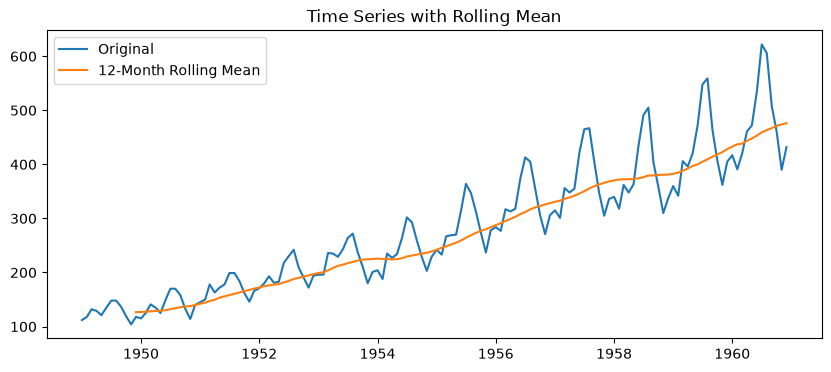

In [9]:
# Plot: original series overlaid with 12-month rolling mean
plt.figure(figsize=(10, 4))
plt.plot(ts, label='Original')
plt.plot(rolling_mean, label='12-Month Rolling Mean')
plt.legend()
plt.title("Time Series with Rolling Mean")
plt.show()

**Interpretation of Exploratory Plot:**

Two key features are immediately visible:

1. **Upward trend** — The 12-month rolling mean rises steadily from ~130 to ~430, confirming a strong positive trend.
2. **Growing seasonal amplitude** — The peaks and troughs widen as the level increases.  This is the hallmark of **multiplicative seasonality**: the seasonal effect is proportional to the level of the series.

These observations have direct modeling implications:
- A simple additive decomposition will leave structured residuals (we will verify this next).
- A **log-transformation** can stabilize the variance and convert multiplicative seasonality into additive, simplifying later modeling.
- Stationarity tests (Step 5) will almost certainly reject the null of stationarity given the obvious trend.



# Step 4 — Time Series Decomposition


**Pre-coding questions**

1. What does the seasonal component represent?      
The seasonal component represents a repeating pattern that occurs at regular intervals. In this dataset, the seasonal period is 12 months, so the seasonal component represents the yearly pattern in airline passenger numbers.


2. What would happen if the seasonal period is incorrect?       
The decomposition would identify the wrong repeating pattern. This could produce misleading trend and residual components and leave important seasonal structure in the residuals. As a result, later forecasting models could also perform poorly.


Perform additive decomposition with seasonal period = 12.

In [10]:
# Additive decomposition — trend + seasonal + residual ---
decomp = seasonal_decompose(ts, model='additive', period=12)

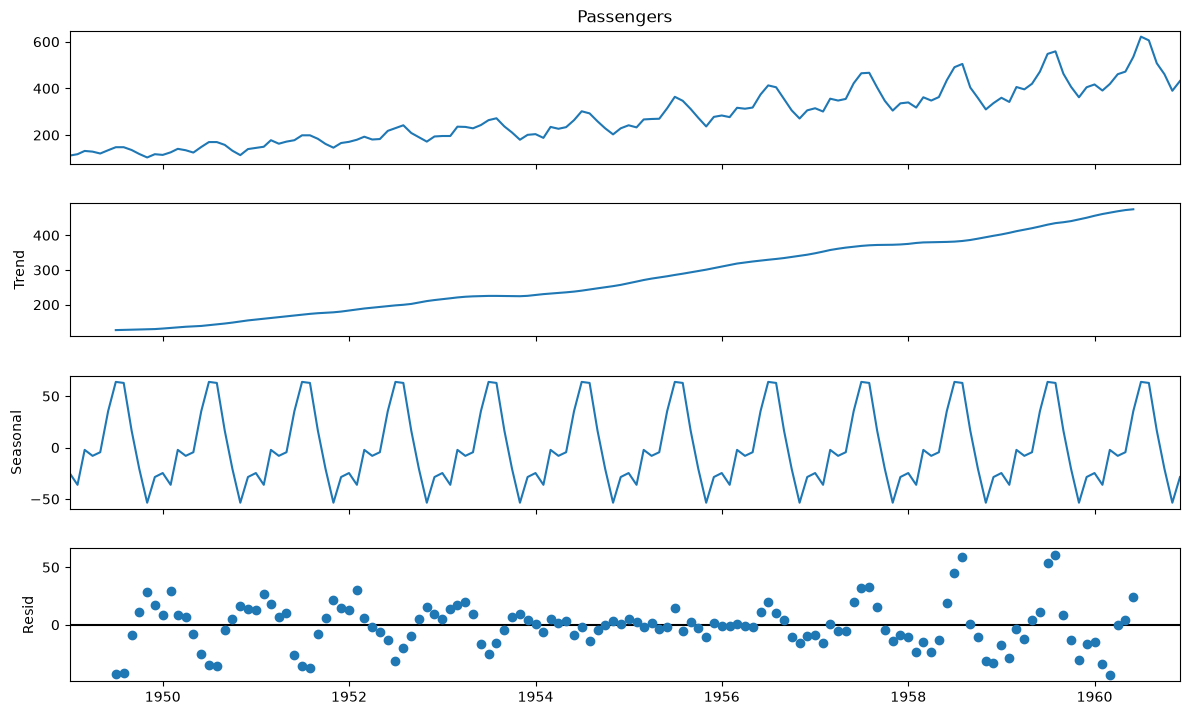

In [11]:
# Visualize decomposed components: observed, trend, seasonal, residual
fig = decomp.plot()
fig.set_size_inches(12, 8)  # Increase plot height to 8 inches
plt.show()

**Interpretation of Additive Decomposition:**

The decomposition separates the series into three components:

- **Trend:** Smoothly increasing from ~120 to ~450, confirming the long-run growth in air travel.
- **Seasonal:** A clear 12-month repeating pattern with peaks in summer (Jul–Aug) and troughs in winter (Nov–Feb). The amplitude is roughly constant (~±40 passengers), which is an artifact of the *additive* assumption.
- **Residuals:** Notice that the residuals are **not** randomly scattered around zero — they show increasing spread over time. This is a strong signal that the additive model is misspecified and a **multiplicative** or **log-additive** decomposition would be more appropriate.

**Key takeaway:** Always inspect residuals after decomposition. Structured residuals indicate model mis-specification.

# Step 5 — Stationarity Testing

Run the Augmented Dickey-Fuller test and observe how the decomposition changes.

In [12]:
# Augmented Dickey-Fuller test on the raw series 
# H0: series has a unit root (non-stationary)
# H1: series is stationary
# Reject H0 if p-value < 0.05

result = adfuller(ts)
print("ADF Statistic:", result[0])
print("p-value:      ", result[1])
print("\nFull output:", result)

ADF Statistic: 0.8153688792060576
p-value:       0.9918802434376411

Full output: (np.float64(0.8153688792060576), np.float64(0.9918802434376411), 13, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(996.692930839019))


**Note on Differencing:**

First-order differencing (`ts.diff()`) removes the linear trend by computing $y'_t = y_t - y_{t-1}$. After differencing:
- The mean should be approximately constant.
- However, the **variance** may still increase over time (because our series has multiplicative seasonality).

For full stationarity, we may also need **seasonal differencing** (lag-12) or a **log-transformation** to stabilize variance before differencing.

Apply first differencing and rerun the ADF test.

In [13]:
# --- First-order differencing: y'_t = y_t - y_{t-1} ---
ts_diff = ts.diff().dropna()

# Re-run ADF on the differenced series
result_diff = adfuller(ts_diff)
print("ADF Statistic (differenced):", result_diff[0])
print("p-value (differenced):      ", result_diff[1])

ADF Statistic (differenced): -2.8292668241699968
p-value (differenced):       0.05421329028382589


# Step 6 — Feature Engineering

**Why Engineer Temporal Features?**

Extracting `month` and `year` from the datetime index enables:
- **Month** — captures seasonal patterns when used in regression-based models (e.g., linear regression, tree-based models).
- **Year** — captures the long-run trend as a numeric feature.

These features are essential for ML-based forecasting approaches (Random Forest, XGBoost, neural networks) but are *not* needed by SARIMA, which captures trend and seasonality through its own differencing and seasonal components.

In [14]:
#  Extract calendar features from the datetime index
df = ts.to_frame()
df['month'] = df.index.month  # 1–12, captures seasonality
df['year']  = df.index.year   # numeric trend proxy

# Step 7 — Baseline Forecasting

Implement exponential smoothing baseline.

In [15]:
# Exponentially Weighted Moving Average baseline (alpha=0.3) ---
# Higher alpha → more weight on recent observations
baseline = ts.ewm(alpha=0.3).mean()

**About the Exponential Smoothing Baseline:**

Exponential Weighted Moving Average (EWMA) with α=0.3 gives more weight to recent observations and less to older ones. It adapts faster than a simple moving average but does not model trend or seasonality explicitly.

**Why baselines matter in ML systems:**
- They set a performance floor — any production model must beat the baseline to justify its complexity.
- A baseline that is hard to beat may indicate that the data is too noisy or the signal is already well-captured by simple methods.
- In monitoring, if a deployed model's accuracy drops below the baseline, it signals **model degradation**.

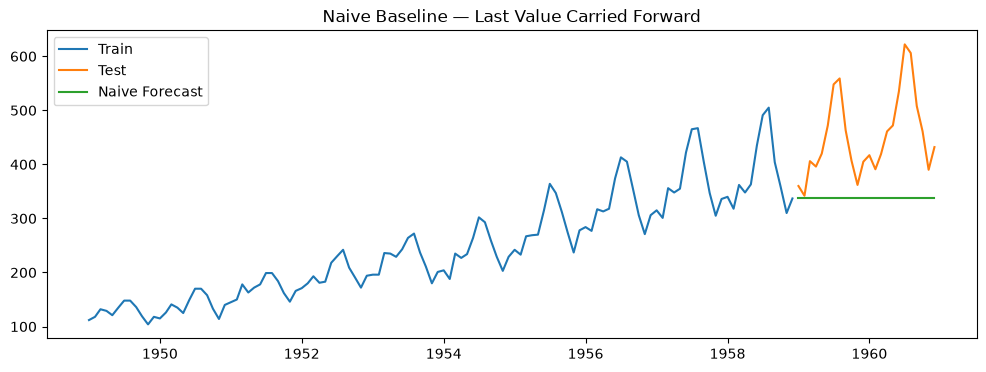

In [16]:
# Naive forecast: last known value repeated for the forecast horizon 
train = ts.iloc[:-24]   # first 120 months for training
test  = ts.iloc[-24:]   # last 24 months held out

# Naive baseline: flat line at the last training value
naive = pd.Series(train.iloc[-1], index=test.index)

plt.plot(train, label="Train")
plt.plot(test, label="Test")
plt.plot(naive, label="Naive Forecast")
plt.legend()
plt.title("Naive Baseline — Last Value Carried Forward")
plt.show()

 ACF and PACF Diagnostics

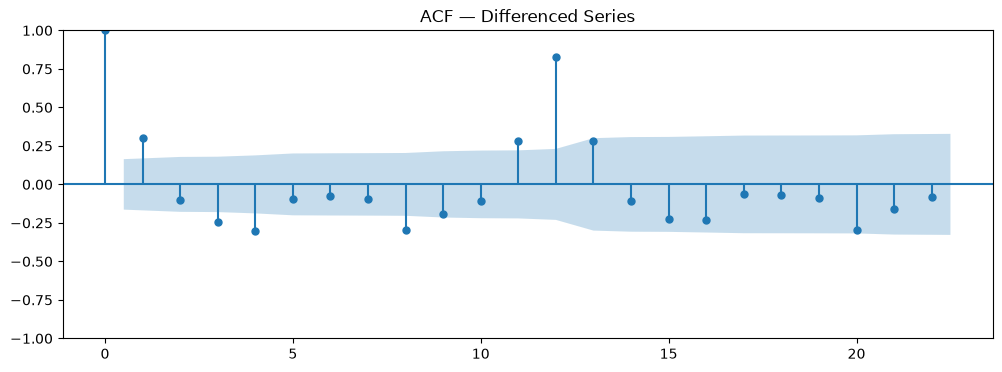

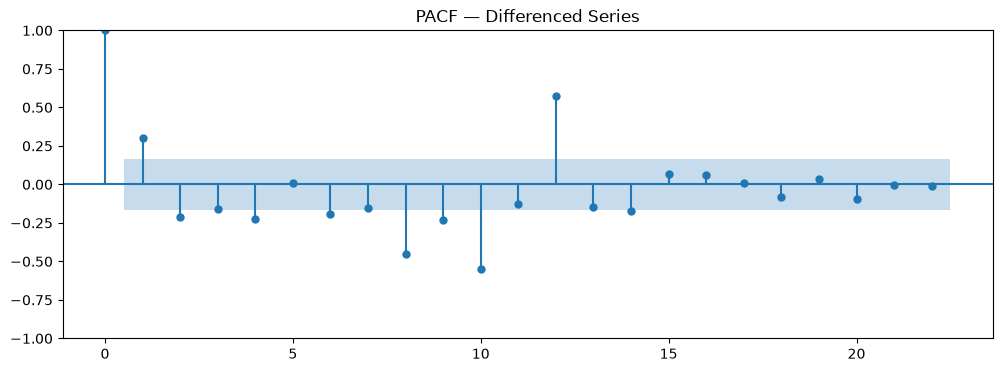

In [17]:
# ACF and PACF of differenced series — guides (p, q) selection 
plot_acf(ts_diff.dropna())
plt.title("ACF — Differenced Series")
plt.show()

plot_pacf(ts_diff.dropna())
plt.title("PACF — Differenced Series")
plt.show()

# Step 8 — SARIMA Modeling

- Propose candidate ARIMA orders based on ACF/PACF.
- Fit SARIMA model (1,1,1)(1,1,1,12).

In [18]:
# Fit SARIMA(1,1,1)(1,1,1,12) 
# order=(p,d,q): AR(1), 1st-order differencing, MA(1)
# seasonal_order=(P,D,Q,m): seasonal AR(1), seasonal diff(1), seasonal MA(1), period 12
model = SARIMAX(ts, order=(1,1,1), seasonal_order=(1,1,1,12))
fit_model = model.fit(disp=False)  # disp=False suppresses optimization output

The model specification means:
- **(1,1,1):** AR(1), differencing order 1, MA(1) — captures short-term dynamics after removing trend.
- **(1,1,1,12):** Seasonal AR(1), seasonal differencing order 1, seasonal MA(1) with period 12 — captures yearly seasonality.


In [19]:
# Model summary: coefficients, significance, AIC/BIC, diagnostics
print(fit_model.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -506.149
Date:                            Fri, 16 Oct 2026   AIC                           1022.299
Time:                                    14:58:16   BIC                           1036.675
Sample:                                01-01-1949   HQIC                          1028.140
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1272      0.356     -0.358      0.721      -0.825       0.570
ma.L1         -0.2148      0.325   

**Interpretation of SARIMA(1,1,1)(1,1,1,12) Results:**

**Key statistics to examine in the summary:**
- **AIC / BIC:** Lower is better; used for model comparison.
- **Coefficients:** Check that AR and MA coefficients are statistically significant (p < 0.05).
- **Ljung-Box (Q):** Tests whether residuals are white noise. A non-significant result (p > 0.05) is desirable.
- **Jarque-Bera:** Tests normality of residuals. Non-normal residuals may affect confidence intervals.

In production, SARIMA models must be periodically retrained as new data arrives and the underlying data-generating process may shift (concept drift).

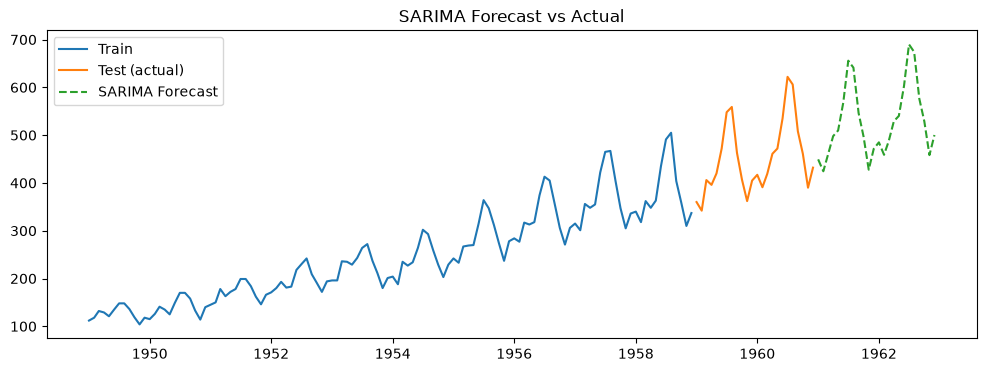

In [20]:
# Forecast next 24 months and compare against held-out test set ---
forecast = fit_model.get_forecast(steps=len(test))
pred = forecast.predicted_mean.copy()

plt.figure(figsize=(12, 4))
plt.plot(train, label="Train")
plt.plot(test, label="Test (actual)")
plt.plot(pred, label="SARIMA Forecast", linestyle='--')
plt.legend()
plt.title("SARIMA Forecast vs Actual")
plt.show()

# Step 9 — Rolling Origin Backtesting

Implement rolling-origin validation.

In [21]:
# Rolling-origin (expanding window) backtesting 
# Train on first 108 months (9 yrs), then forecast 1 step ahead, expand, repeat
train_size = 108
actuals, forecasts = [], []

for end in range(train_size, len(ts)):
    train_window = ts.iloc[:end]                                  # expanding window
    mdl = SARIMAX(train_window, order=(1,1,1), seasonal_order=(1,1,1,12))
    res = mdl.fit(disp=False)
    pred = res.forecast(steps=1).iloc[0]                          # 1-step-ahead
    actuals.append(ts.iloc[end])
    forecasts.append(pred)

# --- Compute error metrics ---
mae  = mean_absolute_error(actuals, forecasts)
rmse = np.sqrt(mean_squared_error(actuals, forecasts))
print(f"Rolling-origin MAE : {mae:.2f}")
print(f"Rolling-origin RMSE: {rmse:.2f}")

Rolling-origin MAE : 12.22
Rolling-origin RMSE: 16.02


**Interpretation of Rolling-Origin Backtesting Results:**

- **MAE ≈ 12.22** — On average, the one-step-ahead forecast is off by about 12 passengers.
- **RMSE ≈ 16.02** — The root-mean-squared error penalizes larger errors more heavily.

Given that the test period covers 1958–1960 when passenger counts ranged from ~300–622, an MAE of ~12 represents roughly a **2–4% error**, which is quite good for a univariate model.

**Why rolling-origin (expanding window) validation?**

Unlike cross-validation for i.i.d. data, time series require **temporal ordering** to be preserved. Rolling-origin validation:
1. Trains on all data up to time *t*
2. Forecasts time *t+1*
3. Slides forward and repeats

This mimics how the model would be used in production — always forecasting the next unseen period using all available historical data.

# Step 10 — Diagnostics and Monitoring

Residuals should resemble **white noise** if the model captures structure.

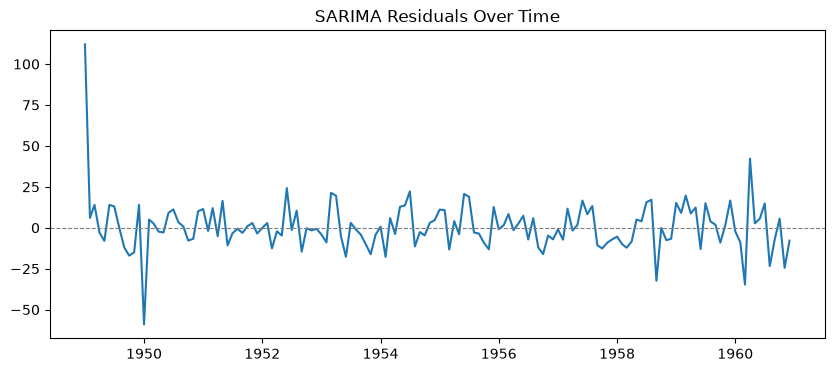

In [22]:
# Residual diagnostics ---
resid = fit_model.resid  # in-sample residuals from the fitted SARIMA

# Time plot of residuals — look for patterns or increasing variance
plt.figure(figsize=(10, 4))
plt.plot(resid)
plt.axhline(y=0, color='grey', linestyle='--', linewidth=0.8)
plt.title("SARIMA Residuals Over Time")
plt.show()


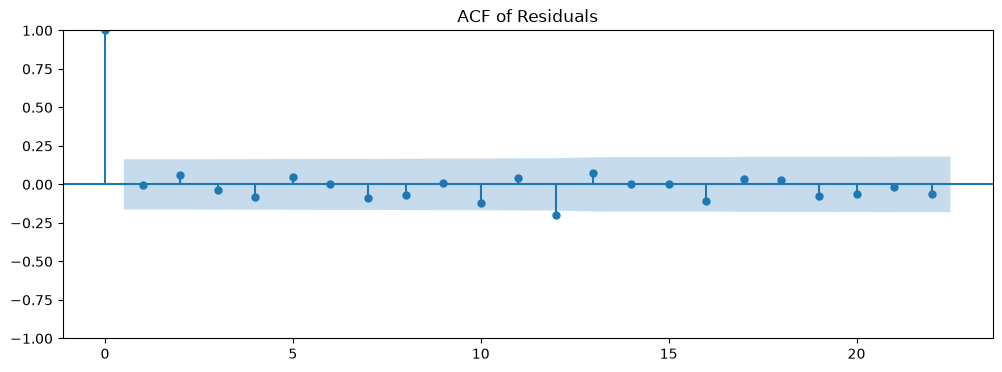

In [23]:

# ACF of residuals — spikes outside the band indicate unmodeled structure
plot_acf(resid)
plt.title("ACF of Residuals")
plt.show()

**Interpretation of Residual Diagnostics:**

**Residuals plot:**  
Ideally, residuals should look like **white noise** — mean zero, constant variance, no visible patterns. If you observe increasing spread or cyclical patterns, it suggests the model is missing structure.

**ACF of residuals:**  
The autocorrelation function (ACF) shows whether residuals at different lags are correlated. For a well-specified model:
- All autocorrelation bars should fall within the blue confidence bands (shaded region).
- Significant spikes at seasonal lags (12, 24, …) would indicate **unmodeled seasonality**.
- Significant spikes at low lags (1, 2, 3) would indicate **unmodeled short-term dynamics**.

If residuals are not white noise, consider:
1. Adding more AR or MA terms
2. Trying a different seasonal period
3. Applying a variance-stabilizing transformation (e.g., log)
4. Using a more flexible model (e.g., Prophet, LSTM)

## Monitoring metrics

Define monitoring metrics for a production forecasting system.


- Forecast MAE / RMSE
- Residual autocorrelation
- Prediction interval coverage
- Data drift detection
- Data pipeline latency


## Reflection

1. Did the SARIMA model outperform the baseline consistently?       
The performance of the model was efficient concerning the results of the rolling-origin procedure: MAE equals 12.22, while RMSE equals 16.02. However, since the provided notebook does not show the numerical values of the MAE and RMSE for the naive baseline, it is impossible to confirm if the improvements were consistent across all the metrics. The usage of the SARIMA model should not be rejected if the error measures of the model are lower than the corresponding measures of the baseline.      

2. What signals would indicate forecast drift in production?        
Signals of forecast drift would include increasing MAE or RMSE, systematic changes in residuals, increasing residual autocorrelation, changes in the distribution of the input data, and prediction intervals that no longer provide appropriate coverage. A new trend or seasonal pattern in the observed data could also indicate that the model needs to be retrained.
   


4. Which monitoring metrics would you log in a deployed forecasting system?     
I would log forecast MAE and RMSE, residual autocorrelation, coverage of prediction intervals, data drift, and data pipeline latency. I would also log the model version, timestamp of the forecast, a predicted value, the actual value in case it becomes available, and the data used to generate the forecast. The five main monitoring metrics identified by the lab are MAE/RMSE, residual autocorrelation, coverage of prediction intervals, data drift, and pipeline latency.



## Additional Analyses for Deeper Understanding

The following cells demonstrate additional techniques that are commonly used in time-series analysis and are relevant to ML systems in production.

### 1: ACF and PACF Plots

The **Autocorrelation Function (ACF)** and **Partial Autocorrelation Function (PACF)** are essential tools for identifying the order of AR and MA components in ARIMA models.
- ACF at lag *k* measures the correlation between $y_t$ and $y_{t-k}$.
- PACF at lag *k* measures the correlation between $y_t$ and $y_{t-k}$ after removing the effects of intermediate lags.

**Rule of thumb for model selection:**
- ACF decays slowly + PACF cuts off at lag *p* → AR(p) model
- ACF cuts off at lag *q* + PACF decays slowly → MA(q) model
- Both decay slowly → ARMA model

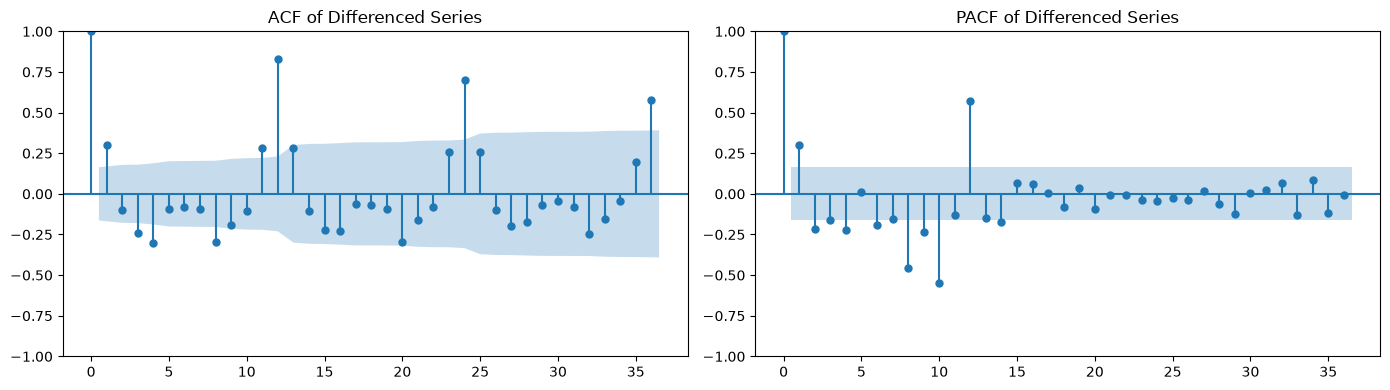

In [24]:
# ACF & PACF with 36 lags to reveal seasonal correlation at lag 12 ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(ts.diff().dropna(), lags=36, ax=axes[0])
axes[0].set_title("ACF of Differenced Series")

plot_pacf(ts.diff().dropna(), lags=36, ax=axes[1])
axes[1].set_title("PACF of Differenced Series")

plt.tight_layout()
plt.show()

### 2: Log Transformation for Variance Stabilization

When the seasonal amplitude grows with the level (multiplicative seasonality), applying a **log transformation** converts the series into one with approximately additive seasonality and constant variance. This often improves ARIMA model performance.

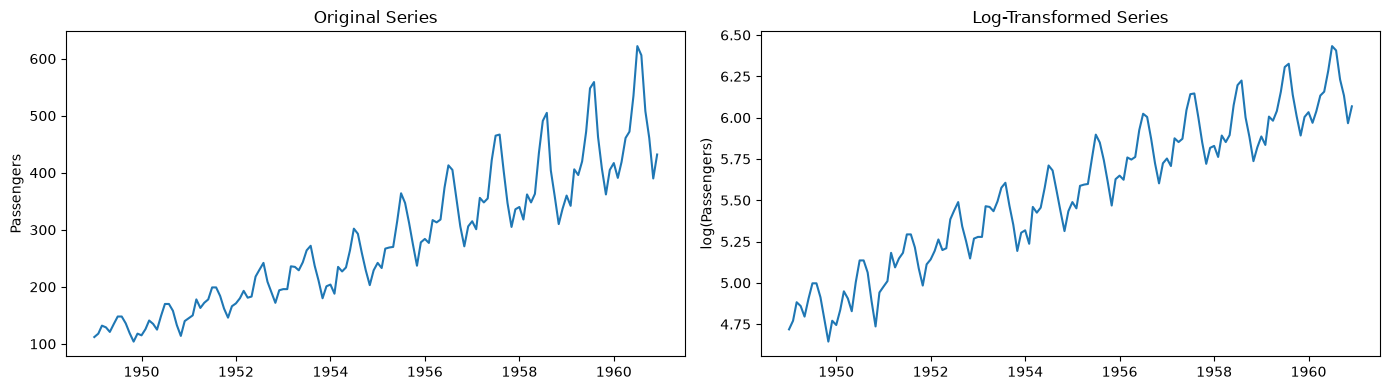

Original series std by year:
Month
1949    13.7
1950    19.1
1951    18.4
1952    23.0
1953    28.5
1954    34.9
1955    42.1
1956    47.9
1957    57.9
1958    64.5
1959    69.8
1960    77.7
Name: Passengers, dtype: float64

Log series std by year:
Month
1949    0.108
1950    0.135
1951    0.108
1952    0.113
1953    0.127
1954    0.144
1955    0.144
1956    0.141
1957    0.152
1958    0.160
1959    0.157
1960    0.157
Name: Passengers, dtype: float64


In [25]:
# Log-transform to stabilize variance ---
ts_log = np.log(ts)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ts)
axes[0].set_title("Original Series")
axes[0].set_ylabel("Passengers")

axes[1].plot(ts_log)
axes[1].set_title("Log-Transformed Series")
axes[1].set_ylabel("log(Passengers)")

plt.tight_layout()
plt.show()

# Compare year-by-year std: log series should have more constant spread
print("Original series std by year:")
print(ts.groupby(ts.index.year).std().round(1))
print("\nLog series std by year:")
print(ts_log.groupby(ts_log.index.year).std().round(3))

### 3: Forecast Visualization

A critical part of any forecasting system is **visualizing predictions against actuals**. This helps stakeholders understand model performance intuitively and can reveal systematic biases.

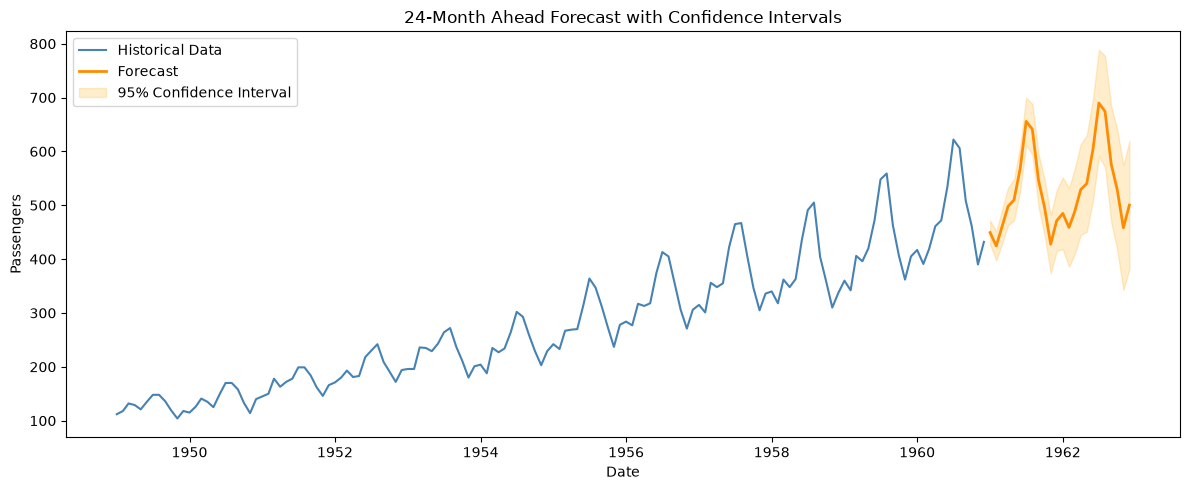

In [26]:
# 24-month forecast with 95% confidence interval ---
forecast_model  = SARIMAX(ts, order=(1,1,1), seasonal_order=(1,1,1,12))
forecast_fit    = forecast_model.fit(disp=False)
forecast_result = forecast_fit.get_forecast(steps=24)
forecast_mean   = forecast_result.predicted_mean
forecast_ci     = forecast_result.conf_int()       # lower & upper 95% bounds

plt.figure(figsize=(12, 5))
plt.plot(ts, label='Historical Data', color='steelblue')
plt.plot(forecast_mean.index, forecast_mean,
         label='Forecast', color='darkorange', linewidth=2)
plt.fill_between(forecast_ci.index,
                 forecast_ci.iloc[:, 0],
                 forecast_ci.iloc[:, 1],
                 color='orange', alpha=0.2, label='95% Confidence Interval')
plt.title("24-Month Ahead Forecast with Confidence Intervals")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.legend()
plt.tight_layout()
plt.show()

**End of Lab**